In [1]:
#Load modules
import pandas as pd
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from numpy import mean
from numpy import absolute
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

In [4]:
#pre-process the data
df = pd.read_csv("marketing_campaign.csv") #load the data

#select features
y= df['Response'] #Select target variable
X = df.drop('Response',axis=1) #Select features
X = pd.get_dummies(X, drop_first=True) 

#Normalize the data
columns = X.columns #create index with column names (needed for last step)
scaler = MinMaxScaler() #initiate the scaler
X = scaler.fit_transform(X) #scale the data
X = pd.DataFrame(X,columns=columns) #turn back into a dataframe

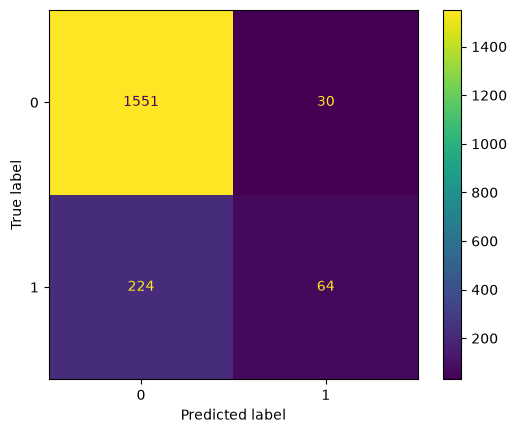

Accuracy: 0.8640984483681113


In [6]:
#Make the prediction
rf = RandomForestClassifier(n_estimators=100, random_state=69)

y_pred = cross_val_predict(rf, X, y, cv=5) #make the predictions

cm = confusion_matrix(y, y_pred) #create the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm) #create the graph
disp.plot() #plot the graph
plt.show() #show the graph

accuracy = (cm.diagonal().sum()) / cm.sum() #calculate accuracy
print("Accuracy:",accuracy) #print accuracy


In [8]:
#Calculate Gini importance
rf = RandomForestClassifier(n_estimators=100, random_state=69) #Define the model
rf.fit(X,y) #Fit the data to the random forest model
feature_importances = rf.feature_importances_ #get the GINI importances

importance_df = pd.DataFrame({ #create a dataframe shat shows the importance for each feature
    'Feature': X.columns,
    'Importance': feature_importances
})

importance_df = importance_df.sort_values(by='Importance', ascending=False) #sort the data from high to low

print(importance_df) #print the result


                    Feature  Importance
5                   Recency    0.100159
6                  MntWines    0.094159
2                    Income    0.087926
8           MntMeatProducts    0.084483
0                        ID    0.064809
11             MntGoldProds    0.064336
1                Year_Birth    0.051180
10         MntSweetProducts    0.050603
14      NumCatalogPurchases    0.049273
15        NumStorePurchases    0.048263
16        NumWebVisitsMonth    0.047509
9           MntFishProducts    0.044486
7                 MntFruits    0.043166
13          NumWebPurchases    0.037314
12        NumDealsPurchases    0.033695
4                  Teenhome    0.014940
24    Marital_Status_Single    0.012334
21            Education_PhD    0.011016
22  Marital_Status_Divorced    0.010850
23   Marital_Status_Married    0.010156
25  Marital_Status_Together    0.009614
19     Education_Graduation    0.008263
3                   Kidhome    0.007112
20         Education_Master    0.006267


In [9]:
#Hyperparameter Tuning (1)
#pre-process the data
df = pd.read_csv("marketing_campaign.csv")

#With logistic regression
y= df['Response']
X = df.drop('Response',axis=1) #Select features
X = pd.get_dummies(X, drop_first=True) 

#Normalize the data
columns = X.columns #create index with column names (needed for last step)
scaler = MinMaxScaler() #initiate the scaler
X = scaler.fit_transform(X) #scale the data
X = pd.DataFrame(X,columns=columns) #turn back into a dataframe

In [10]:
#Hyperparameter Tuning (2)
import optuna
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

# Hyperparameter tuning
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 250, step=10),
        'max_depth': trial.suggest_int('max_depth', 10, 250, step=10),
        'min_samples_split': trial.suggest_int('min_samples_split', 10, 30, step=1),
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']),
        'random_state': 69
    }
    regressor = RandomForestRegressor(**params)
    score = cross_val_score(regressor, X, y, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1).mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)  # search across 100 different combinations

print("Best params:", study.best_params)

/usr/local/python/3.14.2/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-08 10:07:10,299] A new study created in memory with name: no-name-80d9d08f-5c3a-475a-b328-d9dc855dac3c
[I 2026-10-08 10:07:15,767] Trial 0 finished with value: -0.21858918975017616 and parameters: {'n_estimators': 230, 'max_depth': 130, 'min_samples_split': 29, 'max_features': 'log2'}. Best is trial 0 with value: -0.21858918975017616.
[I 2026-10-08 10:07:20,717] Trial 1 finished with value: -0.20753262501494157 and parameters: {'n_estimators': 170, 'max_depth': 50, 'min_samples_split': 17, 'max_features': None}. Best is trial 1 with value: -0.20753262501494157.
[I 2026-10-08 10:07:21,888] Trial 2 finished with value: -0.20785343155459227 and parameters: {'n_estimators': 40, 'max_depth': 30, 'min_samples_split': 27, 'max_

Best params: {'n_estimators': 60, 'max_depth': 220, 'min_samples_split': 11, 'max_features': None}


In [11]:
#Run the optimized model
regressor = RandomForestRegressor(**study.best_params,
                                      random_state=69) 
RFscores = cross_val_score(regressor, X, y, cv=5,
                           scoring='neg_mean_absolute_error')
MAE = mean(absolute(RFscores))
print ('the MAE is: %.2f' % MAE)

the MAE is: 0.21


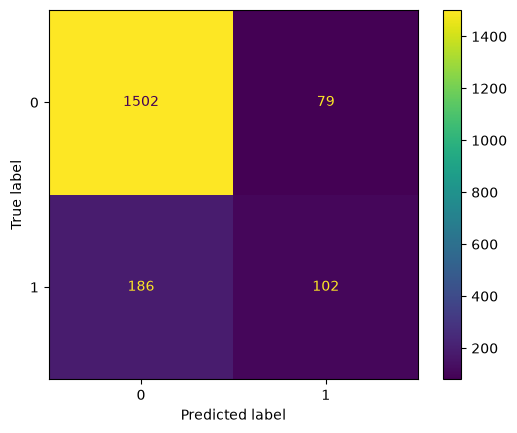

Accuracy: 0.8582129481005886


In [12]:
#Prediction with XGBoost
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Make the prediction
xgb = XGBClassifier(n_estimators=100, random_state=69, eval_metric='logloss')
y_pred = cross_val_predict(xgb, X, y, cv=5)  # make the predictions
cm = confusion_matrix(y, y_pred)  # create the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)  # create the graph
disp.plot()  # plot the graph
plt.show()  # show the graph
accuracy = (cm.diagonal().sum()) / cm.sum()  # calculate accuracy
print("Accuracy:", accuracy)  # print accuracy

In [13]:
import optuna
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
 
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'random_state': 69,
        'eval_metric': 'logloss'
    }
    model = XGBClassifier(**params)
    score = cross_val_score(model, X, y, cv=5, scoring='accuracy').mean()
    return score
 
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)
 
print("Best params:", study.best_params)
print("Best accuracy:", study.best_value)

[I 2026-10-08 10:25:17,486] A new study created in memory with name: no-name-a7ff5836-865c-4e4d-b27b-e3af0d02d1e6
[I 2026-10-08 10:25:17,861] Trial 0 finished with value: 0.8587547131940761 and parameters: {'n_estimators': 67, 'max_depth': 5, 'learning_rate': 0.052608318742867366, 'subsample': 0.6328864097613329, 'colsample_bytree': 0.8396670604629849, 'min_child_weight': 3}. Best is trial 0 with value: 0.8587547131940761.
[I 2026-10-08 10:25:18,979] Trial 1 finished with value: 0.852868059239294 and parameters: {'n_estimators': 417, 'max_depth': 8, 'learning_rate': 0.09489567776358174, 'subsample': 0.5308571368664703, 'colsample_bytree': 0.6441068281863624, 'min_child_weight': 8}. Best is trial 0 with value: 0.8587547131940761.
[I 2026-10-08 10:25:20,150] Trial 2 finished with value: 0.8555475907155452 and parameters: {'n_estimators': 427, 'max_depth': 3, 'learning_rate': 0.16160719743088894, 'subsample': 0.9409002825056724, 'colsample_bytree': 0.6438063298064673, 'min_child_weight': 

Best params: {'n_estimators': 201, 'max_depth': 4, 'learning_rate': 0.17614529666444342, 'subsample': 0.6435771796536984, 'colsample_bytree': 0.5587080048480666, 'min_child_weight': 5}
Best accuracy: 0.869987527060544


**The accuracy of the random forest was:0.8640984483681113**

**The accuracy of the xgboost was: 0.8582129481005886**

**So if you can see the xgboost is more accurate in this situation**